# SR 01 · Discovering pressure-loss scaling

**Chemical Engineering Modelling Labs · Worked teaching edition**

**Introductory SR case · three independent inputs.** Search compact multiplicative equations, estimate their coefficients, compare polynomial baselines and interpret the resulting diameter sensitivity.

## Start here · use in Google Colab
Open this `.ipynb` with **File → Upload notebook**, keep a **CPU runtime**, and use **Runtime → Run all**. Save an individual copy before editing. All data are generated inside the notebook; the core exercise needs no upload, process simulator, API key, GPU or Julia installation.

Every executable line has an adjacent English comment. Markdown between cells explains the scientific purpose and the result to inspect. Saved tables and plots are retained in this worked edition so that it is also readable without running it.

**Teaching contract.** These are synthetic observations, not laboratory measurements. Ground truth is disclosed for teaching and independent audits; model fitting uses noisy training targets only. Validation selects a model; test and challenge sets report performance after selection. Repeatedly redesigning a model after reading test errors invalidates the original test.

**Follow the sequence:** context → data → model structure → fitting → validation → test diagnostics → engineering interpretation → exercises → export.

## 1. Set up Python

In [1]:
import importlib.util  # Check the runtime before installing any packages.
import subprocess  # Run pip through this notebook's Python interpreter when required.
import sys  # Identify the active interpreter and record its version.
requirements = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'scipy': 'scipy', 'statsmodels': 'statsmodels', 'sklearn': 'scikit-learn', 'sympy': 'sympy'}  # Map Python imports to package names.
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]  # Find only the dependencies that are absent.
if missing:  # Keep a working Colab environment unchanged whenever possible.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])  # Install missing packages in the current runtime.
import numpy as np  # Perform numerical array calculations and generate controlled random noise.
import pandas as pd  # Display labelled datasets and result tables.
import matplotlib.pyplot as plt  # Create figures with the default Matplotlib colours.
import scipy  # Record the numerical-library version for reproducibility.
from scipy import stats  # Obtain statistical distributions and diagnostics.
from scipy.optimize import minimize, least_squares  # Optimise operating points and fit nonlinear equation parameters.
import statsmodels.api as sm  # Fit linear-in-coefficient regressions and estimate statistical intervals.
from sklearn.preprocessing import PolynomialFeatures  # Generate polynomial terms for the RSM baselines.
from itertools import combinations, product  # Enumerate experimental-design pairs and symbolic candidate structures.
from pathlib import Path  # Manage output files independently of the operating system.
import json  # Save fitted-model specifications in readable form.
import shutil  # Bundle figures and tables into a downloadable archive.
from IPython.display import display, Markdown, Math, FileLink  # Embed formatted tables, equations and links in the notebook.
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.dpi': 110})  # Keep figure text legible without changing colour or plot style.
pd.set_option('display.max_columns', 16)  # Keep the important columns visible in result tables.
versions = pd.DataFrame({'component': ['Python', 'NumPy', 'pandas', 'SciPy', 'statsmodels'], 'version': [sys.version.split()[0], np.__version__, pd.__version__, scipy.__version__, sm.__version__]})  # Record the environment used for this execution.
display(versions)  # Show the software versions before modelling begins.

,component,version
0,Python,3.13.5
1,NumPy,2.3.5
2,pandas,2.2.3
3,SciPy,1.17.0
4,statsmodels,0.14.6


**Checkpoint.** The version table should appear without an exception. Core dependencies are installed only when absent. Minor numerical differences between package versions are possible.

In [2]:
SEED = 20261010  # Reproduce the original four-case teaching dataset package.
case_seed = np.random.SeedSequence(SEED).spawn(4)[2]  # Select an independent random stream for this chemical-engineering case.
design_seed, noise_seed = case_seed.spawn(2)  # Keep operating-point sampling separate from observation noise.
rng_design = np.random.default_rng(design_seed)  # Generate reproducible experimental conditions.
rng_noise = np.random.default_rng(noise_seed)  # Generate reproducible but independent measurement errors.
RESULTS = Path('results_03_sr_pipe_pressure')  # Store this case's figures, data and fitted-model files in one place.
RESULTS.mkdir(exist_ok=True)  # Reuse the same folder safely when the notebook is rerun.
print('Output folder:', RESULTS.resolve())  # Identify the files that can be downloaded at the end.

Output folder: /mnt/data/Colab_Teaching_Notebooks/results_03_sr_pipe_pressure


**Reproducibility.** The default settings regenerate the corresponding observations in the earlier dataset package. Changing the seed represents a new synthetic experiment; do not choose a seed for favourable performance.

In [3]:
def lhs(n, bounds, rng):  # Spread observations across each input range using Latin hypercube sampling.
    bounds = np.asarray(bounds, dtype=float)  # Convert the physical lower and upper limits into an array.
    u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in bounds])  # Sample every stratum once in each input direction.
    return bounds[:, 0] + u * (bounds[:, 1] - bounds[:, 0])  # Map the samples into the physical operating box.

def save_plot(fig, filename):  # Display and preserve each result figure.
    fig.tight_layout()  # Reduce crowding between labels, axes and titles.
    fig.savefig(RESULTS / (filename + '.png'), dpi=160, bbox_inches='tight')  # Save a high-resolution copy for teaching slides or reports.
    plt.show()  # Embed the figure in the notebook output.
    plt.close(fig)  # Release figure memory before continuing to the next plot.

def metrics(y, prediction):  # Quantify predictions without refitting the model.
    y, prediction = np.asarray(y), np.asarray(prediction)  # Ensure compatible numerical arrays.
    errors = prediction - y  # Define a positive error as an overprediction.
    return {'RMSE': float(np.sqrt(np.mean(errors**2))), 'MAE': float(np.mean(np.abs(errors))), 'R_squared': float(1 - np.sum(errors**2) / np.sum((y-y.mean())**2))}  # Return error magnitudes and the mean-response comparison.

def parity(y, prediction, title, units, filename):  # Compare new observations with fixed-model predictions.
    fig, ax = plt.subplots(figsize=(6.8, 5.2))  # Create a single readable plotting panel.
    ax.scatter(y, prediction, s=26, alpha=0.7)  # Draw one marker per independent evaluation observation.
    limits = [min(np.min(y), np.min(prediction)), max(np.max(y), np.max(prediction))]  # Cover observed and predicted values with the same numerical range.
    ax.plot(limits, limits, '--', label='Perfect prediction')  # Mark the identity line as the reference.
    ax.set(xlabel='Observed '+units, ylabel='Predicted '+units, title=title)  # State the response units and evaluation purpose.
    ax.legend()  # Identify the reference line without cluttering the plot.
    save_plot(fig, filename)  # Save and embed this parity figure.

**Read the helpers.** RMSE and MAE retain the response units. $R^2$ can be negative. A scatter plot is an evaluation tool, not proof of a valid mechanism.

## 2. Engineering question and physical scope
How do flow rate, pipe diameter and viscosity determine the pressure drop in a viscous-liquid transfer line?

| Independent input | Range |
|---|---:|
| Volumetric flow, $Q$ | 0.1–0.6 L min$^{-1}$ |
| Internal diameter, $D$ | 4–8 mm |
| Dynamic viscosity, $\mu$ | 5–20 mPa s |

Use a 2 m measurement section and density $\rho=1000\ \mathrm{kg\,m^{-3}}$. Assume fully developed, steady, incompressible Newtonian laminar flow in a straight horizontal circular pipe. Exclude fittings, entrance losses and elevation changes.

The instructor's generator is Hagen–Poiseuille flow:
$$\Delta P=\frac{128\mu LQ}{\pi D^4},\qquad Re=\frac{4\rho Q}{\pi\mu D}.$$
All quantities must be converted to SI units before applying this equation. With these ranges, the maximum Reynolds number is approximately 637.

Add positive, mean-preserving noise:
$$y_{obs}=y_{true}\exp(\sigma z-\sigma^2/2),\quad z\sim\mathcal N(0,1),\quad \sigma=0.03.$$
The relative scatter is approximately 3%. The $-\sigma^2/2$ term ensures $\mathbb E[y_{obs}\mid x]=y_{true}$. Do not clip negative values from another noise model and call the result equivalent.

In [4]:
FEATURES = ['flow_L_min', 'diameter_mm', 'viscosity_mPa_s']  # Label the three inputs in practical engineering units.
BOUNDS = np.array([[0.1, 0.6], [4, 8], [5, 20]], dtype=float)  # Define the intended training domain.
CENTRE, HALF_RANGE = BOUNDS.mean(axis=1), np.diff(BOUNDS, axis=1).ravel()/2  # Fix a well-scaled coordinate system for RSM comparisons.
REFERENCES = np.array([0.3, 6.0, 10.0])  # Define input reference quantities without supplying the true output coefficient.
P_REFERENCE = 1000.0  # Express pressure relative to one kilopascal when searching numerical expressions.
SIGMA = 0.03  # Set the standard deviation of the multiplicative log-noise.
def pipe_truth(x):  # Evaluate the physical teaching generator using SI units.
    q, d, mu = np.atleast_2d(x).T  # Separate flow, diameter and dynamic viscosity.
    q, d, mu = q*1e-3/60, d*1e-3, mu*1e-3  # Convert litres per minute, millimetres and mPa s into SI units.
    if np.any(q <= 0) or np.any(d <= 0) or np.any(mu <= 0):  # Exclude invalid flow directions and non-positive material or geometric properties.
        raise ValueError('Flow, diameter and viscosity must be positive for this lesson.')  # State the supported domain explicitly.
    reynolds = 4*1000*q/(np.pi*mu*d)  # Check the laminar-flow regime at each requested operating point.
    if np.max(reynolds) >= 1500:  # Keep the generator comfortably within the low-Reynolds-number regime.
        raise ValueError('This teaching generator is restricted to low-Reynolds-number flow.')  # Prevent unsupported regime extension.
    return 128*mu*2*q/(np.pi*d**4)  # Return the pressure drop in pascals over the two-metre section.
print('Reference-condition pressure drop:', pipe_truth(REFERENCES)[0], 'Pa')  # Verify unit conversion at a known operating point.

Reference-condition pressure drop: 3143.801345025093 Pa


**Checkpoint.** The reference-condition drop is approximately 3143.8 Pa. It is generated by the physics, not supplied as the fitted coefficient. A unit mistake in diameter is amplified by its fourth power.

,observations
split,
challenge,100
test,100
train,150
validation,50


,flow_L_min,diameter_mm,viscosity_mPa_s,pressure_observed_Pa,pressure_true_Pa,split
0,0.1295,7.2686,15.8675,982.5583,999.7015,train
1,0.4883,7.1739,15.3658,3854.4054,3847.4692,train
2,0.5435,7.9440,8.0173,1451.3145,1486.1226,train
3,0.3939,4.8978,19.9324,18336.5260,18531.4833,train
4,0.4829,6.9418,7.6350,2243.6543,2156.4532,train
5,0.2280,7.5685,18.4091,1717.3063,1736.8713,train
6,0.5540,6.4036,9.5508,4136.2735,4273.9401,train
7,0.2088,7.2852,8.4726,815.4085,852.8832,train
8,0.1019,5.6053,15.0576,2108.8415,2111.0949,train
9,0.4582,7.9055,16.5796,2737.7981,2641.6136,train


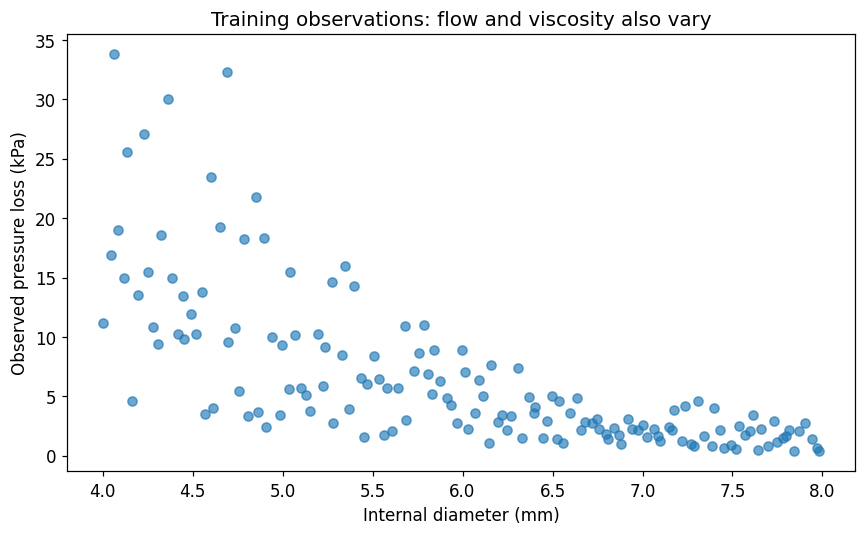

In [5]:
frames = []  # Collect fixed training, validation, test and diameter-challenge datasets.
for split, n in [('train', 150), ('validation', 50), ('test', 100), ('challenge', 100)]:  # Specify all observation budgets before model fitting.
    bounds = BOUNDS.copy()  # Preserve the original training domain.
    if split == 'challenge':  # Define a deliberate geometric extrapolation case.
        bounds[1] = [8, 10]  # Extend only pipe diameter beyond its training range.
    x = lhs(n, bounds, rng_design)  # Sample physical operating conditions across each input range.
    clean = pipe_truth(x)  # Generate the noise-free pressure drops for teaching audits.
    observed = clean*np.exp(SIGMA*rng_noise.normal(size=n)-0.5*SIGMA**2)  # Add positive noise with the correct conditional mean.
    frame = pd.DataFrame(x, columns=FEATURES)  # Attach physical input labels and units.
    frame['pressure_observed_Pa'], frame['pressure_true_Pa'], frame['split'] = observed, clean, split  # Keep observed and noise-free responses separate.
    frames.append(frame)  # Store the independent data partition.
data = pd.concat(frames, ignore_index=True)  # Assemble the complete synthetic flow experiment.
train, validation, test, challenge = [data[data['split'].eq(s)].reset_index(drop=True) for s in ['train', 'validation', 'test', 'challenge']]  # Create purpose-specific data tables.
data.to_csv(RESULTS/'synthetic_data.csv', index=False)  # Save the generated dataset with explicit provenance.
display(data.groupby('split').size().to_frame('observations'))  # Confirm the four data budgets.
display(train.head(10).round(4))  # Inspect a representative subset of the noisy observations.
fig, ax = plt.subplots(figsize=(8, 5))  # Create one training-data overview figure.
ax.scatter(train['diameter_mm'], train['pressure_observed_Pa']/1000, alpha=0.65)  # Show pressure against diameter while the other two inputs also vary.
ax.set(xlabel='Internal diameter (mm)', ylabel='Observed pressure loss (kPa)', title='Training observations: flow and viscosity also vary')  # Prevent interpreting a multivariable scatter as a one-input experiment.
save_plot(fig, '01_training_observations')  # Save the initial data overview.

**Interpretation.** The scatter is not a pure diameter response because flow and viscosity vary simultaneously. The surrogate must account for all three inputs.

## 3. Separate the symbolic structure from its coefficient
Use dimensionless inputs $u=Q/Q_0$, $v=D/D_0$, $w=\mu/\mu_0$ and $y=\Delta P/(1000\ \mathrm{Pa})$.

Our transparent core algorithm searches
$$\hat y=A u^{p_Q}v^{p_D}w^{p_\mu},\quad p_Q,p_D,p_\mu\in\{-5,-4,\ldots,3\}.$$
It checks **729 structures**, including missing-variable structures when an exponent is zero. For each exponent triple, it fits one positive coefficient $A$ from noisy training data.

Because the noise is multiplicative,
$$\log y_{obs}+\sigma^2/2=\log A+p_Q\log u+p_D\log v+p_\mu\log w+\epsilon,$$
where $\mathbb E[\epsilon]=0$. The training optimum for $\log A$ is the mean corrected-log residual for that structure.

**This is restricted symbolic structure search.** The algorithm is supplied a multiplicative power-law family and an integer-exponent range. It is not unrestricted genetic programming and does not independently discover the power-law assumption. A fixed-exponent fit would estimate only $A$; this algorithm also chooses the exponents and which inputs appear.

In [6]:
Utrain = train[FEATURES].to_numpy()/REFERENCES  # Form dimensionless training inputs using fixed physical references.
Uval = validation[FEATURES].to_numpy()/REFERENCES  # Apply the same transformation to validation inputs.
log_train = np.log(train['pressure_observed_Pa'].to_numpy()/P_REFERENCE)+0.5*SIGMA**2  # Correct the known synthetic log-noise mean for training.
log_val = np.log(validation['pressure_observed_Pa'].to_numpy()/P_REFERENCE)+0.5*SIGMA**2  # Use the same target convention for validation scoring.
EXPONENTS = range(-5, 4)  # Define the allowed integer powers before searching any equations.
rows = []  # Collect the fitted coefficient, errors and complexity of every candidate structure.
for powers in product(EXPONENTS, repeat=3):  # Enumerate all 729 three-input exponent structures.
    powers = np.asarray(powers)  # Represent this formula's three exponents as an array.
    log_a = np.mean(log_train-np.log(Utrain)@powers)  # Fit the log coefficient using training data only.
    train_error = np.sqrt(np.mean((log_a+np.log(Utrain)@powers-log_train)**2))  # Quantify the candidate's training log residuals.
    val_error = np.sqrt(np.mean((log_a+np.log(Uval)@powers-log_val)**2))  # Score generalisation to independent validation data.
    complexity = 1+sum(abs(int(p))+2 for p in powers if p != 0)  # Penalise additional factors and higher absolute powers with a stated teaching proxy.
    rows.append({'p_Q': int(powers[0]), 'p_D': int(powers[1]), 'p_mu': int(powers[2]), 'A': float(np.exp(log_a)), 'complexity': complexity, 'train_log_RMSE': train_error, 'validation_log_RMSE': val_error})  # Retain a complete search record.
search = pd.DataFrame(rows)  # Convert all candidate formulas into a sortable model-selection table.
TOLERANCE = 0.002  # Predeclare the allowed absolute log-RMSE increase when favouring a simpler equation.
shortlist = search[search['validation_log_RMSE'] <= search['validation_log_RMSE'].min()+TOLERANCE]  # Retain candidates essentially tied on validation accuracy under this rule.
selected = shortlist.sort_values(['complexity', 'validation_log_RMSE']).iloc[0]  # Prefer the least complex model inside the validation tolerance.
powers = selected[['p_Q', 'p_D', 'p_mu']].to_numpy(dtype=int)  # Freeze the three selected exponents.
A = float(selected['A'])  # Freeze the coefficient fitted from training data.
display(search.sort_values('validation_log_RMSE').head(12).round(5))  # Show the strongest candidates rather than only the winning equation.
print('Selected structure:', powers, '; fitted A:', A)  # Report the actual structure found in this run.
search.to_csv(RESULTS/'all_symbolic_candidates.csv', index=False)  # Save the complete structural search for inspection.

,p_Q,p_D,p_mu,A,complexity,train_log_RMSE,validation_log_RMSE
501,1,-4,1,3.14301,13,0.02832,0.02870
510,1,-3,1,3.20393,12,0.19889,0.19780
492,1,-5,1,3.08324,14,0.20096,0.20120
502,1,-4,2,2.69044,14,0.38436,0.38038
500,1,-4,0,3.67170,10,0.38187,0.38398
519,1,-2,1,3.26604,11,0.39579,0.39419
511,1,-3,2,2.74259,13,0.43121,0.41074
491,1,-5,0,3.60188,11,0.42996,0.41572
493,1,-5,2,2.63928,15,0.43343,0.44567
509,1,-3,0,3.74287,9,0.43027,0.44724


Selected structure: [ 1 -4  1] ; fitted A: 3.143005145055606


**Read the results.** The selected exponents should be obtained from the table, not hard-coded. With the default data the physically expected scaling is favoured. Complexity here is a declared within-search proxy, not an exact expression-tree node count or a universal comparison with RSM coefficients.

DeltaP_hat = 1000*3.1430051*(Q/0.3)^(1)*(D/6)^(-4)*(mu/10)^(1) Pa


<IPython.core.display.Math object>

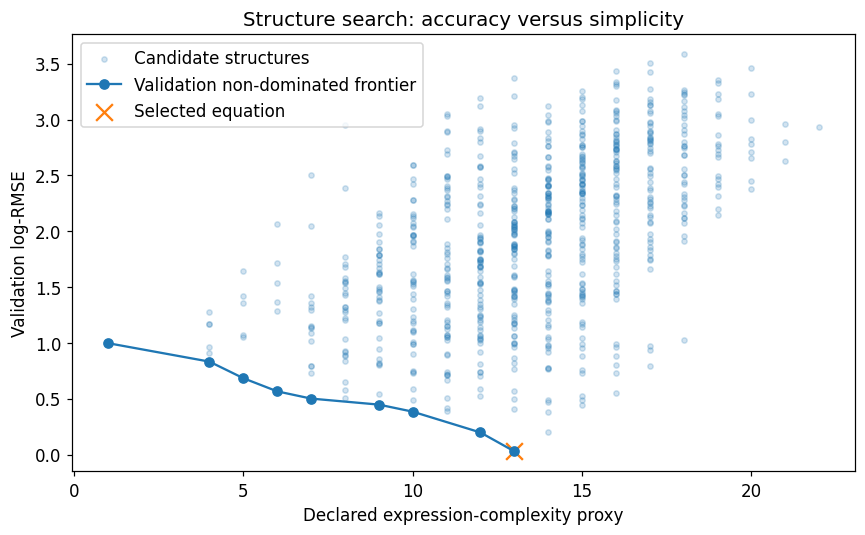

In [7]:
def sr_predict(x, coefficient=A):  # Evaluate the selected symbolic model in physical pressure units.
    inputs = np.atleast_2d(x)/REFERENCES  # Apply exactly the same dimensionless input definitions used during fitting.
    return P_REFERENCE*coefficient*np.prod(inputs**powers, axis=1)  # Reconstruct pressure from the frozen formula and coefficient.
equation = f'DeltaP_hat = 1000*{A:.7f}*(Q/0.3)^({powers[0]})*(D/6)^({powers[1]})*(mu/10)^({powers[2]}) Pa'  # Write the learned expression with input units defined above.
print(equation)  # Display the actual fitted formula in a copyable format.
display(Math(r'\frac{\widehat{\Delta P}}{1000\,\mathrm{Pa}}='+f'{A:.6f}'+r'\left(\frac{Q}{0.3\,\mathrm{L\,min}^{-1}}\right)^{'+str(powers[0])+r'}\left(\frac{D}{6\,\mathrm{mm}}\right)^{'+str(powers[1])+r'}\left(\frac{\mu}{10\,\mathrm{mPa\,s}}\right)^{'+str(powers[2])+'}'))  # Render the same equation with readable mathematical notation.
frontier = search.sort_values(['complexity', 'validation_log_RMSE']).groupby('complexity', as_index=False).first()  # Find the most accurate candidate at each complexity level.
frontier = frontier[frontier['validation_log_RMSE'] <= frontier['validation_log_RMSE'].cummin()]  # Retain only complexity levels that improve validation error.
fig, ax = plt.subplots(figsize=(8, 5))  # Create an error-versus-expression-size teaching plot.
ax.scatter(search['complexity'], search['validation_log_RMSE'], s=12, alpha=0.2, label='Candidate structures')  # Show the cost of restricting the expression family.
ax.plot(frontier['complexity'], frontier['validation_log_RMSE'], '-o', label='Validation non-dominated frontier')  # Trace the simple-to-accurate trade-off.
ax.scatter([selected['complexity']], [selected['validation_log_RMSE']], marker='x', s=120, label='Selected equation')  # Identify the chosen trade-off explicitly.
ax.set(xlabel='Declared expression-complexity proxy', ylabel='Validation log-RMSE', title='Structure search: accuracy versus simplicity')  # Distinguish this frontier from an engineering-objective Pareto set.
ax.legend()  # Identify the candidate cloud and selected formula.
save_plot(fig, '02_symbolic_frontier')  # Preserve the structure-search visualisation.

**Interpretation.** The structure contains engineering information: exponents describe multiplicative scaling. Recovering a plausible exponent is not proof that a model remains valid in turbulent or non-Newtonian flow.

## 4. Compare baselines fairly
Fit a quadratic to raw pressure, a quadratic to the corrected log pressure, and a continuous power law using log-linear least squares. The continuous power law is a fixed functional family, not an unrestricted SR algorithm. All use the same noisy training observations; only the representation and training objective differ.

In [8]:
def coded(x):  # Express physical inputs relative to the fixed design centre and half-range.
    return (np.atleast_2d(x) - CENTRE) / HALF_RANGE  # Map low and high factor levels to minus and plus one.

def design_matrix(x, degree=2):  # Generate a preselected polynomial structure for RSM.
    poly = PolynomialFeatures(degree=degree, include_bias=True)  # Include an intercept and every term up to the requested degree.
    matrix = poly.fit_transform(coded(x))  # Build polynomial features without using any response data.
    names = poly.get_feature_names_out([f'x{i+1}' for i in range(len(CENTRE))])  # Label the main, squared and interaction terms.
    return pd.DataFrame(matrix, columns=names)  # Preserve interpretable coefficient names in the regression output.

def lack_of_fit(model, x, y):  # Separate within-setting noise from possible inadequacy of the polynomial.
    _, groups = np.unique(np.asarray(x), axis=0, return_inverse=True)  # Identify replicated input conditions.
    pure_sse = sum(np.sum((y[groups == g] - y[groups == g].mean())**2) for g in np.unique(groups))  # Measure variation among repeat observations.
    pure_df = len(y) - len(np.unique(groups))  # Count the pure-error degrees of freedom.
    lof_df = int(model.df_resid) - pure_df  # Allocate remaining residual degrees of freedom to lack of fit.
    lof_sse = max(float(np.sum(model.resid**2)) - pure_sse, 0.0)  # Remove measured repeatability from the residual sum of squares.
    f_stat = (lof_sse/lof_df) / (pure_sse/pure_df)  # Compare lack-of-fit variance with the repeatability estimate.
    p_value = stats.f.sf(f_stat, lof_df, pure_df)  # Evaluate the lack-of-fit upper-tail probability.
    return pd.DataFrame({'source': ['Lack of fit', 'Pure error'], 'sum_squares': [lof_sse, pure_sse], 'df': [lof_df, pure_df], 'F': [f_stat, np.nan], 'p_value': [p_value, np.nan]})  # Present the diagnostic in a compact table.

**Method distinction.** The quadratic baselines use centred physical inputs. The power-law models use logarithmic or dimensionless inputs. This is a teaching comparison of representations, not a universal algorithm ranking.

In [9]:
raw_rsm = sm.OLS(train['pressure_observed_Pa'], design_matrix(train[FEATURES])).fit()  # Fit a conventional second-order raw-response surface.
log_rsm = sm.OLS(log_train, design_matrix(train[FEATURES])).fit()  # Fit the same polynomial family to the corrected log response.
power_matrix = np.column_stack((np.ones(len(train)), np.log(Utrain)))  # Predefine an intercept and three continuous logarithmic exponents.
power_fit = sm.OLS(log_train, power_matrix).fit()  # Estimate a continuous power law without discrete structure search.
def all_predictions(x):  # Apply every baseline without changing its training fit.
    x = np.atleast_2d(x)  # Support a single physical operating point or a batch.
    raw = np.asarray(raw_rsm.predict(design_matrix(x)))  # Preserve any negative raw-polynomial predictions for an honest audit.
    logarithmic = P_REFERENCE*np.exp(log_rsm.predict(design_matrix(x)))  # Map the corrected-log polynomial back to positive pressure.
    continuous = P_REFERENCE*np.exp(np.column_stack((np.ones(len(x)), np.log(x/REFERENCES)))@power_fit.params)  # Evaluate the fitted continuous power-law baseline.
    return {'Raw-response RSM': raw, 'Log-response RSM': np.asarray(logarithmic), 'Continuous power law': np.asarray(continuous), 'Restricted SR': sr_predict(x)}  # Return labelled predictions in pascals.
display(pd.DataFrame({'coefficient': power_fit.params}, index=['log_A', 'Q_exponent', 'D_exponent', 'viscosity_exponent']).round(5))  # Show the continuous exponent estimates for comparison with discrete search.

,coefficient
log_A,1.14552
Q_exponent,1.00392
D_exponent,-3.99473
viscosity_exponent,0.99714


**Noise caution.** The known synthetic noise correction is supplied as part of the lesson. With real data, log transformation and back-transformation require their own noise-model assessment; the correction is not automatically known.

,split,model,reference,RMSE,MAE,R_squared,relative_RMSE_pct,nonpositive_predictions
0,test,Raw-response RSM,observed,1303.9030,961.5287,0.9638,74.3412,6
1,test,Raw-response RSM,true,1378.4586,972.4149,0.9608,73.5349,6
2,test,Log-response RSM,observed,535.5445,276.7946,0.9939,4.8971,0
3,test,Log-response RSM,true,361.4177,209.4960,0.9973,3.6119,0
4,test,Continuous power law,observed,301.2640,157.6170,0.9981,3.0445,0
5,test,Continuous power law,true,20.0984,12.2744,1.0000,0.2607,0
6,test,Restricted SR,observed,301.7534,157.0818,0.9981,2.9826,0
7,test,Restricted SR,true,2.4466,1.6969,1.0000,0.0253,0
8,challenge,Raw-response RSM,observed,7740.3164,6138.6579,-179.9929,2514.9591,0
9,challenge,Raw-response RSM,true,7741.8953,6138.8611,-179.8307,2517.7316,0


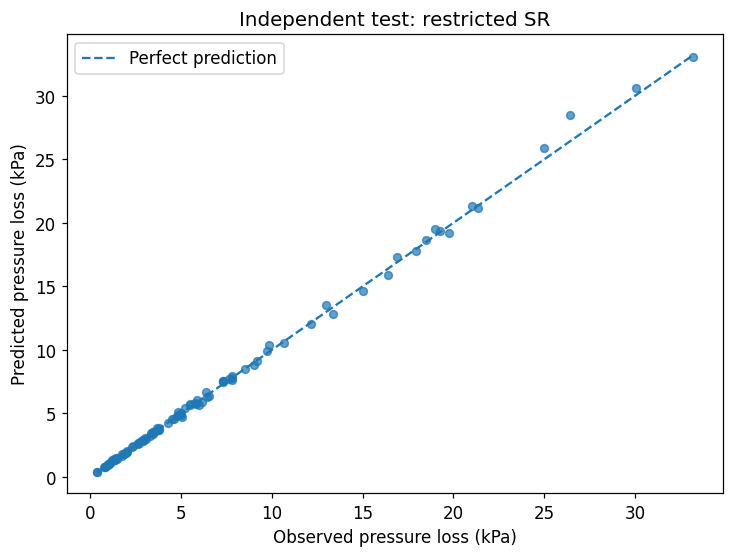

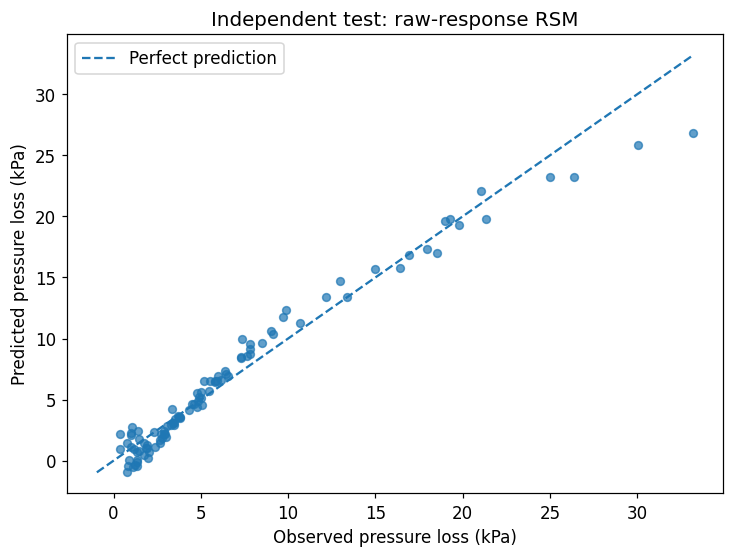

In [10]:
metric_rows = []  # Collect interpolation and extrapolation results only after the symbolic model is frozen.
for split, frame in [('test', test), ('challenge', challenge)]:  # Evaluate each independent regime separately.
    predictions = all_predictions(frame[FEATURES])  # Predict the same inputs using every trained model.
    output = frame.copy()  # Retain source observations with the model predictions.
    for name, values in predictions.items():  # Score every baseline and the selected symbolic equation.
        output[name] = values  # Store row-level predictions without clipping non-physical values.
        for reference in ['observed', 'true']:  # Distinguish observation error from approximation of the noise-free response.
            y = frame['pressure_'+reference+'_Pa'].to_numpy()  # Select the evaluation reference explicitly.
            metric_rows.append({'split': split, 'model': name, 'reference': reference, **metrics(y, values), 'relative_RMSE_pct': 100*np.sqrt(np.mean(((values-y)/y)**2)), 'nonpositive_predictions': int(np.sum(values <= 0))})  # Report absolute error, relative error and physical failures together.
    output.to_csv(RESULTS/(split+'_predictions.csv'), index=False)  # Save individual predictions for auditing.
model_metrics = pd.DataFrame(metric_rows)  # Create a complete comparison table.
display(model_metrics.round(4))  # Reveal why a high overall R-squared can coexist with poor relative accuracy.
model_metrics.to_csv(RESULTS/'model_metrics.csv', index=False)  # Preserve the fixed-model test and challenge results.
parity(test['pressure_observed_Pa']/1000, sr_predict(test[FEATURES])/1000, 'Independent test: restricted SR', 'pressure loss (kPa)', '03_sr_parity')  # Show the symbolic model's physical-scale test predictions.
parity(test['pressure_observed_Pa']/1000, all_predictions(test[FEATURES])['Raw-response RSM']/1000, 'Independent test: raw-response RSM', 'pressure loss (kPa)', '04_rsm_parity')  # Show the same test observations for the polynomial baseline.

**Interpretation.** Large pressure drops can dominate raw-scale RMSE and $R^2$. Relative error and non-positive prediction counts reveal behaviour at low pressure. Diameter extrapolation is a separate challenge, not a promise of universal extrapolation ability.

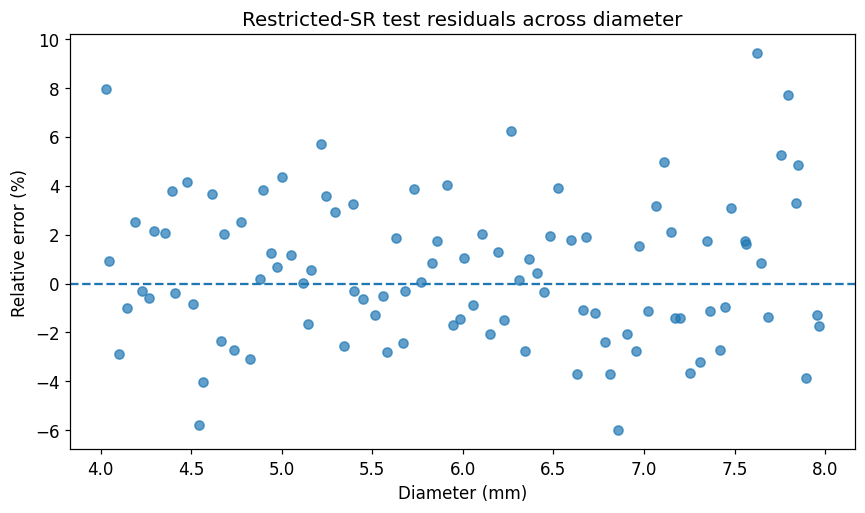

Conditional bootstrap 95% interval for A: [3.13054191 3.15561616]


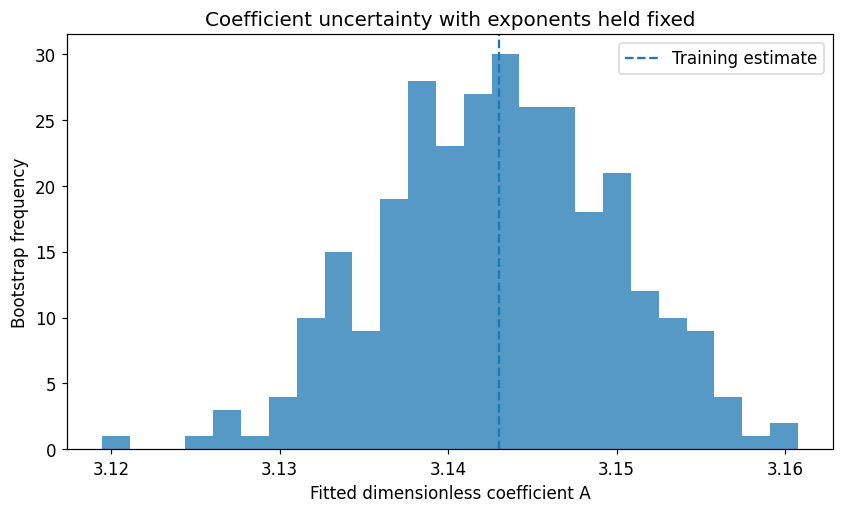

In [11]:
relative_error = 100*(sr_predict(test[FEATURES])-test['pressure_observed_Pa'].to_numpy())/test['pressure_observed_Pa'].to_numpy()  # Express each symbolic prediction error relative to its observed pressure.
fig, ax = plt.subplots(figsize=(8, 4.8))  # Create a relative-error diagnostic for the selected model.
ax.scatter(test['diameter_mm'], relative_error, alpha=0.7)  # Check whether the learned diameter scaling leaves a systematic residual trend.
ax.axhline(0, linestyle='--')  # Mark the unbiased-relative-error reference.
ax.set(xlabel='Diameter (mm)', ylabel='Relative error (%)', title='Restricted-SR test residuals across diameter')  # State the relative-error convention clearly.
save_plot(fig, '05_relative_residuals')  # Save the sensitivity diagnostic.
bootstrap_rng = np.random.default_rng(SEED+3001)  # Create an independent resampling stream for coefficient uncertainty.
bootstrap_coefficients = []  # Collect resampled coefficients conditional on the selected exponent structure.
for _ in range(300):  # Repeat the same fitted-structure coefficient estimate on bootstrap samples.
    indices = bootstrap_rng.integers(0, len(train), len(train))  # Resample complete training observations with replacement.
    estimate = np.exp(np.mean(log_train[indices]-np.log(Utrain[indices])@powers))  # Re-estimate only A for this resampled training set.
    bootstrap_coefficients.append(estimate)  # Retain the coefficient estimate for its empirical sampling distribution.
interval = np.quantile(bootstrap_coefficients, [0.025, 0.975])  # Calculate a percentile interval conditional on the chosen structure.
print('Conditional bootstrap 95% interval for A:', interval)  # Report coefficient uncertainty without claiming structural uncertainty coverage.
fig, ax = plt.subplots(figsize=(7.8, 4.8))  # Create one bootstrap-distribution figure.
ax.hist(bootstrap_coefficients, bins=25, alpha=0.75)  # Display variability in the refitted coefficient.
ax.axvline(A, linestyle='--', label='Training estimate')  # Mark the coefficient used in the final symbolic formula.
ax.set(xlabel='Fitted dimensionless coefficient A', ylabel='Bootstrap frequency', title='Coefficient uncertainty with exponents held fixed')  # State the important conditioning assumption.
ax.legend()  # Identify the fitted reference value.
save_plot(fig, '06_coefficient_bootstrap')  # Save the uncertainty figure.

**Interpretation.** These bootstrap intervals ignore uncertainty from choosing the exponent structure. A full uncertainty analysis would repeat both structure selection and coefficient fitting, and would still need to address physical-model inadequacy.

## 5. Use the equation to reason about a design
Vary diameter while holding flow and viscosity at the reference values. Then inspect a flow–diameter surface and check whether the formula behaves consistently with the assumed laminar-flow regime.

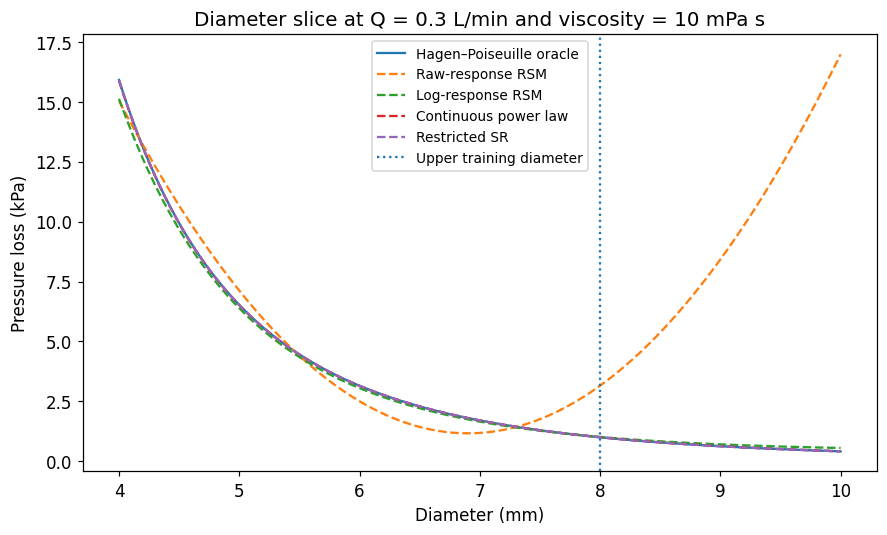

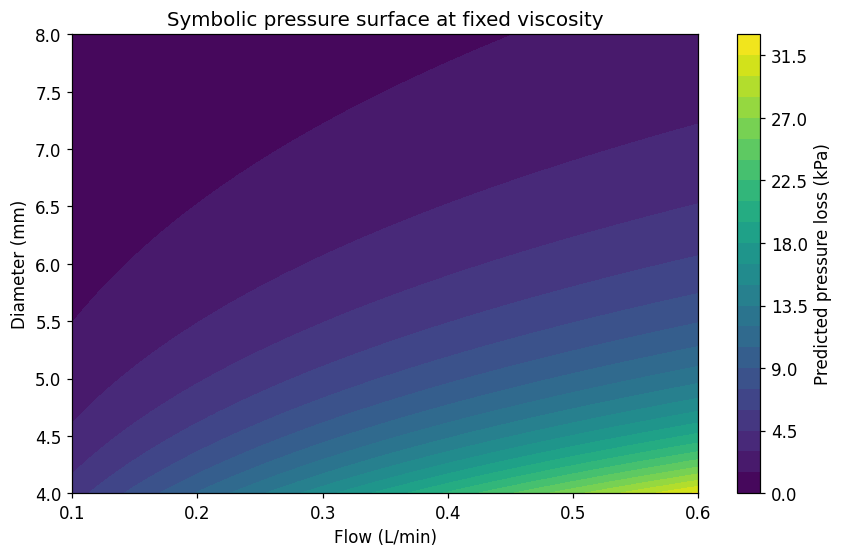

Predicted pressure ratio when diameter doubles: 0.0625
Oracle ratio under unchanged laminar assumptions: 0.0625


In [12]:
xline = np.tile(REFERENCES, (200, 1))  # Hold flow and viscosity fixed at their reference conditions.
xline[:, 1] = np.linspace(4, 10, len(xline))  # Vary diameter across both the fitting and challenge regions.
fig, ax = plt.subplots(figsize=(8.2, 5))  # Create a physically interpretable one-input slice.
ax.plot(xline[:, 1], pipe_truth(xline)/1000, label='Hagen–Poiseuille oracle')  # Display the generating pressure-loss relationship.
for name, values in all_predictions(xline).items():  # Compare each fitted representation under identical conditions.
    ax.plot(xline[:, 1], values/1000, '--', label=name)  # Reveal differences in interpolation and geometric extrapolation.
ax.axvline(8, linestyle=':', label='Upper training diameter')  # Mark the boundary of the fitted diameter domain.
ax.set(xlabel='Diameter (mm)', ylabel='Pressure loss (kPa)', title='Diameter slice at Q = 0.3 L/min and viscosity = 10 mPa s')  # State the held input values and response units.
ax.legend(fontsize=9)  # Keep all model labels readable without crowding the figure.
save_plot(fig, '07_diameter_slice')  # Preserve the engineering scaling comparison.
qg, dg = np.meshgrid(np.linspace(0.1, 0.6, 65), np.linspace(4, 8, 65))  # Form a two-input grid within the fitted regime.
xgrid = np.column_stack((qg.ravel(), dg.ravel(), np.full(qg.size, 10.0)))  # Hold viscosity at 10 mPa s.
fig, ax = plt.subplots(figsize=(8, 5.2))  # Create a separate pressure-surface contour figure.
contour = ax.contourf(qg, dg, sr_predict(xgrid).reshape(qg.shape)/1000, levels=20)  # Evaluate the selected symbolic formula on the display grid.
fig.colorbar(contour, ax=ax, label='Predicted pressure loss (kPa)')  # Label the pressure scale.
ax.set(xlabel='Flow (L/min)', ylabel='Diameter (mm)', title='Symbolic pressure surface at fixed viscosity')  # State which two inputs are changing.
save_plot(fig, '08_pressure_surface')  # Save the full two-input engineering view.
print('Predicted pressure ratio when diameter doubles:', 2.0**powers[1])  # Translate the discovered exponent into a direct scaling statement.
print('Oracle ratio under unchanged laminar assumptions:', 1/16)  # Compare with the known physical scaling without changing the fitted model.

**Engineering takeaway.** A fourth-power diameter dependence gives a factor-of-16 pressure reduction when diameter doubles at fixed flow and viscosity. Applying this ratio outside the assumed flow regime still requires physical verification; the formula does not model fittings or turbulence.

## 6. Exercises and discussion
**A · Search space:** remove $-4$ from `EXPONENTS`. Does the algorithm recover the correct law, or only the best law remaining in the restricted family?

**B · Omitted input:** force the viscosity exponent to zero. Explain the residual variation that follows.

**C · Units:** change input units correctly and incorrectly. Explain why a numerical coefficient alone has no meaning without variable definitions.

**D · Noise:** compare known-noise log correction with ignoring that correction. Separate a coefficient bias from a structure-selection error.

<details><summary><b>Instructor interpretation</b></summary>
An absent structure cannot be recovered by searching harder in the same family. Omitting viscosity creates unmodelled variation correlated with viscosity. A dimensional coefficient changes with units, while the physical prediction should not. A favourable scaling outside the sampled diameter range arises here because the correct physical family was supplied and remains valid; it is not evidence that arbitrary SR equations extrapolate reliably.
</details>

In [13]:
Xtrain_optional, Xval_optional, Xtest_optional = Utrain, Uval, test[FEATURES].to_numpy()/REFERENCES  # Supply the same dimensionless physical inputs to the optional evolutionary search.
ytrain_optional = train['pressure_observed_Pa'].to_numpy()/P_REFERENCE  # Use scaled noisy training pressure for the optional raw-response loss.
yval_optional = validation['pressure_observed_Pa'].to_numpy()/P_REFERENCE  # Keep the optional validation target separate from training.
ytest_optional = test['pressure_observed_Pa'].to_numpy()/P_REFERENCE  # Reserve independent test pressure for reporting only.

**Preparation for the extension.** This cell only defines arrays. It does not install or run PySR.

## Optional extension · evolutionary symbolic regression with PySR
The core search above enumerates a **restricted grammar**. This extension searches a broader space of expression trees with a different algorithm. It is **disabled by default**, is not required to complete the lesson, and is not part of the saved core execution check. Enabling it installs PySR and may initialise/download its Julia runtime; internet access and a working hosted runtime are required.

The search below uses unweighted squared error on the scaled raw output. That differs from the core log-residual objective: treat it as an algorithm demonstration, not a controlled accuracy benchmark. The validation set selects among the returned equations, and non-finite or non-positive candidates receive an infinite validation score. Exact recovery is not guaranteed with this deliberately limited search budget.

Set `RUN_PYSR = True` only after the core notebook has completed. Search settings and package versions can change the discovered expressions.

In [14]:
RUN_PYSR = False  # Keep the complete core lesson runnable without Julia or an additional package installation.
if RUN_PYSR:  # Enter the optional evolutionary search only when the learner explicitly enables it.
    if importlib.util.find_spec('pysr') is None:  # Avoid reinstalling an already available PySR package.
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pysr'])  # Install the optional Python interface in the current runtime.
    from pysr import PySRRegressor  # Import the evolutionary search interface and initialise its Julia dependency when needed.
    evolutionary = PySRRegressor(niterations=40, binary_operators=['+', '-', '*', '/'], unary_operators=['square'], maxsize=24, random_state=SEED, parallelism='serial', deterministic=True, progress=False)  # Define a restrained expression-tree search with reproducible serial settings.
    evolutionary.fit(Xtrain_optional, ytrain_optional)  # Fit using only the supplied noisy training targets.
    optional_rows = []  # Collect independent validation scores for the discovered expression candidates.
    for i in range(len(evolutionary.equations_)):  # Consider each equation returned by the search.
        pv = np.asarray(evolutionary.predict(Xval_optional, index=i))  # Evaluate that expression on untouched validation inputs.
        valid = np.isfinite(pv).all() and np.all(pv > 0)  # Reject undefined, overflowing or non-positive predictions for this positive response.
        error = float(np.sqrt(np.mean((np.log(pv)-np.log(yval_optional))**2))) if valid else np.inf  # Use a relative-scale validation metric without silently clipping invalid outputs.
        optional_rows.append({'equation_index': i, 'validation_log_RMSE': error})  # Record the score separately from training search fitness.
    optional_scores = pd.DataFrame(optional_rows)  # Assemble the validation comparison table.
    display(evolutionary.equations_)  # Show the discovered expressions and their training complexity measures.
    display(optional_scores)  # Show how the independent validation ranking differs from the training ranking.
    finite = optional_scores[np.isfinite(optional_scores['validation_log_RMSE'])]  # Retain only candidates valid on every validation input.
    if len(finite):  # Avoid selecting an invalid expression when every candidate fails the domain check.
        optional_best = int(finite.loc[finite['validation_log_RMSE'].idxmin(), 'equation_index'])  # Select the candidate from validation performance only.
        pt = np.asarray(evolutionary.predict(Xtest_optional, index=optional_best))  # Evaluate the chosen expression on independent test inputs.
        display(pd.DataFrame([metrics(ytest_optional, pt)]))  # Report test metrics in the scaled output units.
        print('Selected optional equation:', evolutionary.sympy(index=optional_best))  # Print the actual expression found in this optional run.
    else:  # Report failure honestly instead of presenting a fabricated symbolic model.
        print('No discovered equation was valid across the validation set; retain the core model for this lesson.')  # Explain the outcome without altering held-out results.
else:  # Make the skipped optional extension explicit in a normal Run all execution.
    print('Optional PySR search skipped. The fully executed core results above remain available.')  # Distinguish tested core outputs from an unexecuted extension.

Optional PySR search skipped. The fully executed core results above remain available.


**Comparison question.** Which structural information did the restricted grammar provide in advance? Which did the evolutionary search need to construct? Compare accuracy, complexity and validity separately, and keep the test set out of repeated search tuning.

## Export your results
All figures, generated observations, model coefficients and prediction tables are saved in the case-specific results folder. Download the archive before disconnecting a temporary runtime. Use **File → Download → Download .ipynb** to retain your own comments and outputs.

In [15]:
model_spec = {'method': 'restricted integer-exponent structure search', 'powers': powers.tolist(), 'A': A, 'input_reference': REFERENCES.tolist(), 'pressure_reference_Pa': P_REFERENCE, 'noise_sigma': SIGMA, 'seed': SEED}  # Record all information needed to evaluate the learned formula.
(RESULTS/'selected_model.json').write_text(json.dumps(model_spec, indent=2), encoding='utf-8')  # Save a transparent machine-readable model specification.
(RESULTS/'selected_equation.txt').write_text(equation, encoding='utf-8')  # Save the copyable physical-unit equation.

65

In [16]:
archive = shutil.make_archive(str(RESULTS) + '_results', 'zip', RESULTS)  # Bundle this run's tables and figures into one archive.
display(FileLink(archive))  # Display a file link in notebook interfaces that support local downloads.
DOWNLOAD_RESULTS = False  # Set this switch to True to start a Colab browser download.
if DOWNLOAD_RESULTS:  # Avoid an unsolicited download during normal Run all execution.
    try:  # Use Colab's helper only in an environment where it exists.
        from google.colab import files  # Load Google's browser-download interface.
        files.download(archive)  # Copy the result archive to the learner's computer.
    except ImportError:  # Keep the same notebook usable in standard Jupyter.
        print('Use the link above or the notebook file browser.')  # Explain the non-Colab download route.
print('Core workflow finished: all displayed core results were calculated in this run.')  # Mark successful completion of the lesson.

/mnt/data/Colab_Teaching_Notebooks/results_03_sr_pipe_pressure_results.zip

Core workflow finished: all displayed core results were calculated in this run.


**Save your work.** Downloading the archive does not itself save edits to the notebook. Save both the `.ipynb` and the results archive.

## Sources and scope
All numerical chemical parameters and synthetic observations are teaching assumptions. The sources support the modelling concepts, not those invented parameter values.

- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)
- [NIST: response surface designs](https://www.itl.nist.gov/div898/handbook/pri/section3/pri336.htm)
- [statsmodels: ordinary least squares](https://www.statsmodels.org/stable/examples/notebooks/generated/ols.html)
- [SciPy: bounded nonlinear least squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)
- [Hagen–Poiseuille tutorial and assumptions](https://carpentry.medunigraz.at/examples/tutorials/tutorials.06_fluid.01_HagenPouseille_Stationary.run.html)
- [PySR method paper](https://arxiv.org/abs/2305.01582)
- [PySR API reference](https://ai.damtp.cam.ac.uk/pysr/api)


**Verification boundary.** The supplied core workflow was executed in a clean local Python kernel and its outputs are saved. This is not a claim of execution in Google's hosted runtime. Any optional PySR section is disabled by default and excluded from the core execution check.